In [1]:
from sklearn.model_selection import train_test_split
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.preprocessing import MinMaxScaler, StandardScaler
import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt



In [2]:
df=pd.read_csv(r"C:\Users\acer\Downloads\Exp-1.csv")
df

,Input,Output
0,1,2
1,2,4
2,3,6
3,4,8
4,5,10
5,6,12
6,7,14
7,8,16
8,9,18
9,10,20


In [3]:
x=df[["Input"]].values
y=df[["Output"]].values

In [4]:
xt,xst,yt,yst=train_test_split(x,y,test_size=0.2,random_state=52) # check if requires_grad is true, false if not directly specified


In [6]:
scale1=MinMaxScaler()
scale2=MinMaxScaler()
xt=scale1.fit_transform(xt)
xst=scale1.transform(xst)


In [7]:
xt=torch.FloatTensor(xt)
xst=torch.FloatTensor(xst)
yt=torch.FloatTensor(yt)
yst=torch.FloatTensor(yst)

In [8]:
class neuralNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(1, 16),
            nn.ReLU(),
            nn.Linear(16, 8),
            nn.ReLU(),
            nn.Linear(8, 1)


        )
    def forward(self, x):
        return self.network(x)

In [9]:
model=neuralNetwork()
criterion=nn.MSELoss()
optimizer=torch.optim.Adam(model.parameters(),lr=0.01)

In [10]:
epochs=5000
losses=[]

for i in range(epochs):
    optimizer.zero_grad()
    predictions=model(xt)
    loss=criterion(predictions,yt)
    loss.backward()
    optimizer.step()
    if i%100==0:
        print(f"epoch: {i}, loss: {loss.item()}")
        losses.append(loss.item())
# %% prediction
new_data=torch.FloatTensor([[16]])
new_data=torch.Tensor(scale1.transform(new_data))
predictions=model(new_data)
print(predictions.item())
# %% test
xst = torch.FloatTensor(xst)
yst = torch.FloatTensor(yst)
with torch.no_grad():
    predictions_l=model(xst)
    test_loss=criterion(predictions_l,yst)
    print(f"test loss: {test_loss.item()}")

epoch: 0, loss: 384.66552734375
epoch: 100, loss: 19.288549423217773
epoch: 200, loss: 0.029834769666194916
epoch: 300, loss: 0.0003900120500475168
epoch: 400, loss: 0.0002341920044273138
epoch: 500, loss: 0.00012931256787851453
epoch: 600, loss: 6.571226549567655e-05
epoch: 700, loss: 3.076138091273606e-05
epoch: 800, loss: 1.3258664694149047e-05
epoch: 900, loss: 5.256992153590545e-06
epoch: 1000, loss: 1.9140977656206815e-06
epoch: 1100, loss: 6.384268544934457e-07
epoch: 1200, loss: 1.9446815713308752e-07
epoch: 1300, loss: 5.37447952808634e-08
epoch: 1400, loss: 1.3598348225229984e-08
epoch: 1500, loss: 3.167864859321412e-09
epoch: 1600, loss: 6.839447341810967e-10
epoch: 1700, loss: 1.3765581730051935e-10
epoch: 1800, loss: 3.0775975518038123e-11
epoch: 1900, loss: 7.579122225653823e-12
epoch: 2000, loss: 2.9416469260468148e-12
epoch: 2100, loss: 1.1226575225009583e-12
epoch: 2200, loss: 1.9184653865522705e-12
epoch: 2300, loss: 1.0042336970675358e-12
epoch: 2400, loss: 9.1423168

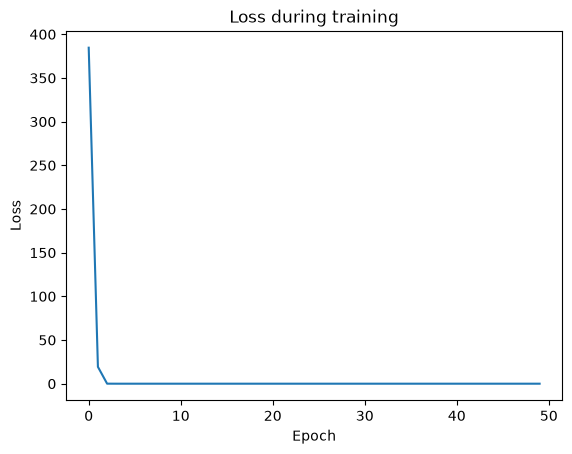

In [11]:
plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss during training")
plt.show()